# Case File 02: The Interrogation
**Objective 2 · Statistical analysis and exploratory data analysis**

**The case.** Hosts and guests both say "Superhosts charge more" and "the city centre is expensive."
Are those claims supported by the data, or just folklore?

**The witness.** The cleaned Airbnb file from Case File 01 (`data/processed/listings_clean.csv`).
Reusing it means any mistake in my cleaning shows up here, which is realistic practice.

**Rule for this notebook:** a p-value alone is not a finding. Every test gets an effect size and a plain-English verdict.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from pathlib import Path
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
df = pd.read_csv("../data/processed/listings_clean.csv")
print(df.shape)
df.describe().T.round(2)

(457, 22)


,count,mean,std,min,25%,50%,75%,max
id,457.0,9.733424e+17,6.012948e+17,2992450.00,6.897193e+17,1.100877e+18,1.473501e+18,1.773591e+18
host_id,457.0,2.639577e+16,2.119318e+17,649068.00,4.937201e+07,2.128860e+08,4.667901e+08,1.767798e+18
host_since,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_response_rate,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_is_superhost,457.0,4.700000e-01,5.000000e-01,0.00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
latitude,457.0,4.266000e+01,1.000000e-02,42.63,4.265000e+01,4.266000e+01,4.267000e+01,4.268000e+01
longitude,457.0,-7.378000e+01,2.000000e-02,-73.83,-7.379000e+01,-7.378000e+01,-7.376000e+01,-7.374000e+01
accommodates,457.0,3.430000e+00,2.520000e+00,1.00,2.000000e+00,2.000000e+00,4.000000e+00,1.600000e+01
bedrooms,457.0,1.650000e+00,1.230000e+00,0.00,1.000000e+00,1.000000e+00,2.000000e+00,9.000000e+00
beds,457.0,1.850000e+00,1.270000e+00,1.00,1.000000e+00,1.000000e+00,2.000000e+00,1.000000e+01


## 1. Distribution check: is price normal?
Almost never. If price is skewed, I should use medians, logs and non-parametric tests.

Skewness of price:     3.82
Skewness of log price: 0.32


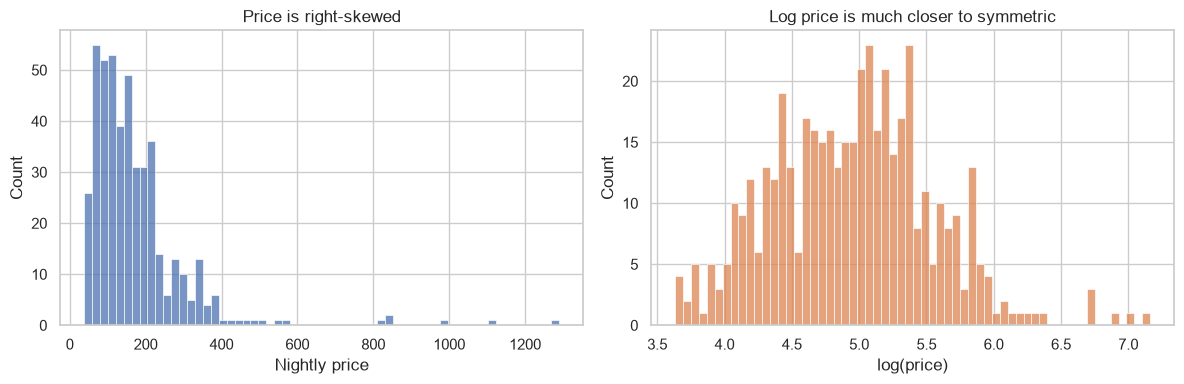

In [2]:
print("Skewness of price:    ", round(stats.skew(df["price"]), 2))
print("Skewness of log price:", round(stats.skew(np.log(df["price"])), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=ax[0])
ax[0].set(title="Price is right-skewed", xlabel="Nightly price")
sns.histplot(np.log(df["price"]), bins=60, ax=ax[1], color="C1")
ax[1].set(title="Log price is much closer to symmetric", xlabel="log(price)")
plt.tight_layout()
plt.savefig(FIG / "02_price_distribution.png", dpi=200)
plt.show()

## 2. Exploratory plots

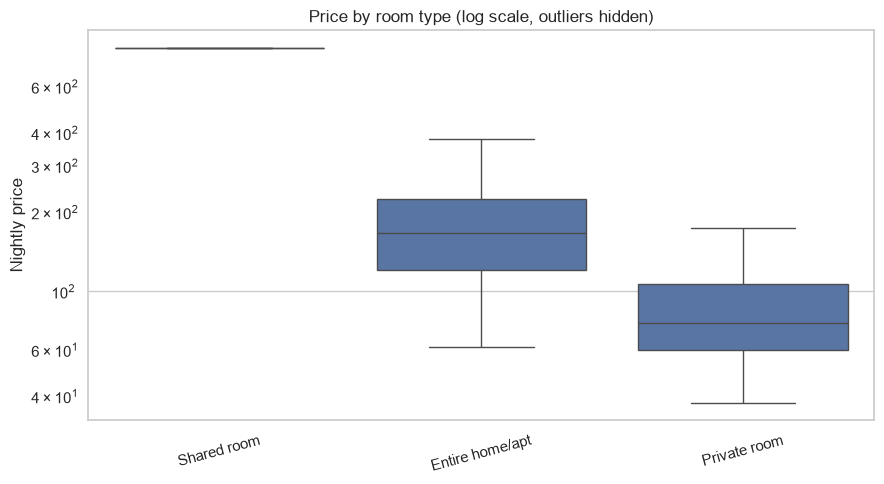

In [3]:
order = df.groupby("room_type")["price"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="room_type", y="price", order=order, ax=ax, showfliers=False)
ax.set(yscale="log", title="Price by room type (log scale, outliers hidden)", xlabel="", ylabel="Nightly price")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIG / "02_price_by_room_type.png", dpi=200)
plt.show()

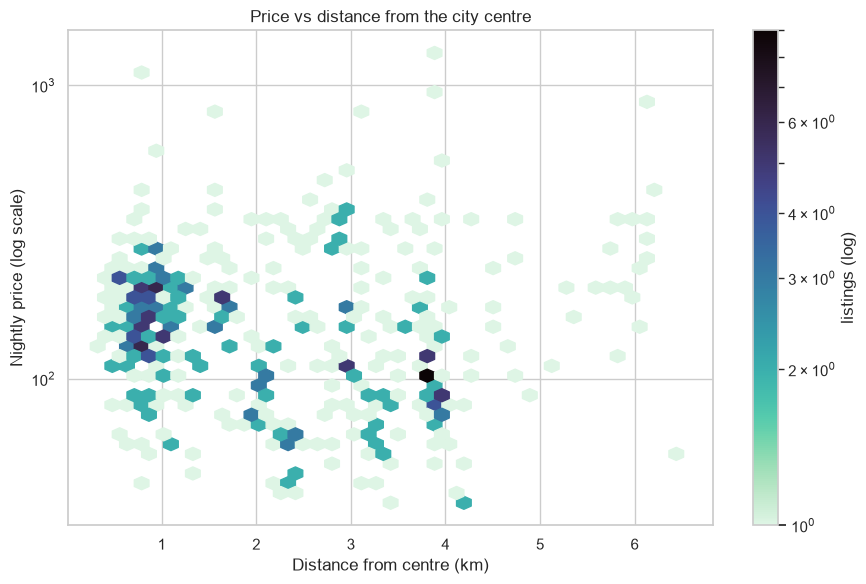

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(df["dist_centre_km"], df["price"], gridsize=40, bins="log", cmap="mako_r", yscale="log", mincnt=1)
plt.colorbar(hb, label="listings (log)")
ax.set(title="Price vs distance from the city centre", xlabel="Distance from centre (km)", ylabel="Nightly price (log scale)")
plt.tight_layout()
plt.savefig(FIG / "02_distance_vs_price.png", dpi=200)
plt.show()

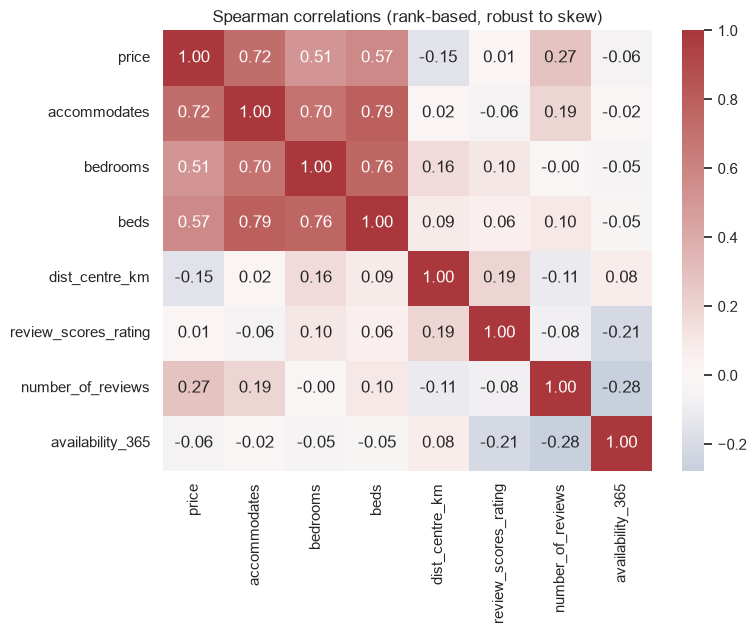

In [5]:
num_cols = ["price", "accommodates", "bedrooms", "beds", "dist_centre_km", "review_scores_rating",
            "number_of_reviews", "availability_365", "host_tenure_years"]
num_cols = [c for c in num_cols if c in df.columns and df[c].notna().any()]   # skip empty columns
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Spearman correlations (rank-based, robust to skew)")
plt.tight_layout()
plt.savefig(FIG / "02_spearman_heatmap.png", dpi=200)
plt.show()

## 3. Claim 1: Superhosts charge more
Mann–Whitney U makes no normality assumption, which suits skewed prices. The bootstrap gives a confidence interval for the *size* of the difference in medians.

In [6]:
a = df.loc[df["host_is_superhost"] == 1, "price"].to_numpy()
b = df.loc[df["host_is_superhost"] == 0, "price"].to_numpy()

u_stat, p_value = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Median superhost: {np.median(a):.0f} | non-superhost: {np.median(b):.0f} | p = {p_value:.4g}")

rng = np.random.default_rng(42)
diffs = [np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(2000)]
ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
print(f"Median difference (superhost - other) 95% CI: [{ci_low:.1f}, {ci_high:.1f}]")

Median superhost: 154 | non-superhost: 128 | p = 0.0007122
Median difference (superhost - other) 95% CI: [3.0, 45.5]


### Confounder check
Is the Superhost premium real, or are Superhosts just more likely to run bigger homes?

In [7]:
by_room = df.groupby(["room_type", "host_is_superhost"])["price"].median().unstack()
by_room.columns = ["not superhost", "superhost"]
by_room["difference"] = by_room["superhost"] - by_room["not superhost"]
by_room.round(1)

,not superhost,superhost,difference
room_type,,,
Entire home/apt,154.2,174.1,19.9
Private room,68.5,80.5,12.0
Shared room,840.0,NaN,NaN


In [8]:
# Same comparison controlling for size: median price within each guest-capacity band
df["capacity_band"] = pd.cut(df["accommodates"], [0, 2, 4, 6, 100], labels=["1-2", "3-4", "5-6", "7+"])
(df.groupby(["capacity_band", "host_is_superhost"], observed=True)["price"].median().unstack()
   .rename(columns={0: "not superhost", 1: "superhost"}).round(1))

host_is_superhost,not superhost,superhost
capacity_band,,
1-2,87.5,115.0
3-4,151.6,185.0
5-6,234.4,245.0
7+,299.0,349.0


## 4. Claim 2: closer to the centre means pricier

In [9]:
rho, p = stats.spearmanr(df["dist_centre_km"], df["price"])
print(f"Spearman rho (distance vs price): {rho:.3f}, p = {p:.4g}")

Spearman rho (distance vs price): -0.152, p = 0.001141


## 5. Claim 3: price differs across room types

In [10]:
# Only compare room types with at least 5 listings (a group of 1 says nothing)
sizes = df["room_type"].value_counts()
kept = sizes[sizes >= 5].index.tolist()
print("Room types compared:", kept, "| left out:", sizes[sizes < 5].index.tolist())
groups = [g["price"].to_numpy() for name, g in df.groupby("room_type") if name in kept]
h_stat, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis across room types: H = {h_stat:.1f}, p = {p:.4g}")
df.groupby("room_type")["price"].agg(["count", "median"]).round(1)

Room types compared: ['Entire home/apt', 'Private room'] | left out: ['Shared room']
Kruskal-Wallis across room types: H = 148.3, p = 4.053e-34


,count,median
room_type,,
Entire home/apt,327,167.0
Private room,129,76.0
Shared room,1,840.0


## Verdicts (fill in from the output above)
| Claim | Test | Result | Effect size | Verdict |
|---|---|---|---|---|
| Superhosts charge more | Mann–Whitney U + bootstrap CI | | | |
| Closer to centre = pricier | Spearman | | | |
| Price differs by room type | Kruskal–Wallis | | | |

**Lesson:** on a large dataset almost any difference is "significant". What matters is *how big* it is, and whether something else (room type, size, location) explains it.